# Eight battery materials: composition and SOC

Ground truth from `generate_spatial_scan_more.py`: eight materials at five SOC values. These are independent electrode coupons on an Al holder, not balanced full cells. Running this notebook does not start SIMNRA. Requires numpy, matplotlib and the local ibeamlab package. Run from the repository root or `examples/`.


In [1]:
from pathlib import Path
import csv
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "examples/generate_spatial_scan_more.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run from the repository root or beneath it")
sys.path.insert(0, str(ROOT / "examples"))
import generate_spatial_scan_more as scan
OUTPUT = ROOT / "examples/datasets/simulated_battery_plots"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

def finish(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"{scan.ARRAY_ROWS} x {scan.ARRAY_COLUMNS} disks; holder "
      f"{scan.HOLDER_WIDTH_MM:g} x {scan.HOLDER_HEIGHT_MM:g} mm")
print("Figures:", OUTPUT)


8 x 5 disks; holder 56 x 89 mm
Figures: D:\ibeamlab\examples\datasets\simulated_battery_plots


## Literature and modelling choices

For one electron per Li/Na, **Δx = Q M / (F/3.6)** with Q in mAh/g and M in g/mol. Cathodes assume discharged x=1 and infer charged x from reversible capacity. These are representative windows, not measurements of both absolute endpoints or universal limits. Rate, cutoff voltage, coatings and irreversible reactions affect the conversion.

| Material | Basis |
|---|---|
| NMC111 | 160.1 mAh/g, bare material, 1C, 2.8–4.3 V vs Li, room temperature; [Kim et al.](https://www.iieta.org/download/file/fid/25173) |
| LFP | 160 mAh/g at 0.2C reported for LFP/C, approximated on the LiFePO4 active-material mass basis; [Zhao et al.](https://doi.org/10.1016/j.electacta.2017.09.176) |
| LMO | Choose 125 mAh/g within reported 120–130, 3.5–4.2 V vs Li; [original study](https://doi.org/10.1016/S0378-7753(02)00063-0) |
| Sodium NFM | 135 mAh/g at 0.1C, 2.0–4.1 V vs Na; undoped literature comparator in [SI Table S4](https://www.rsc.org/suppdata/d4/se/d4se01730g/d4se01730g1.pdf) |
| Graphite | Ideal C6 → LiC6; zero residual Li assumed; [Tang et al.](https://doi.org/10.1149/2.089308jes) |
| Silicon | Ideal Si → Li15Si4 (3.75 Li/Si) at room temperature, not a recommended durability window; [Tang et al.](https://doi.org/10.1149/2.089308jes) |
| Silicon–carbon | Assumed 10 wt% Si / 90 wt% active graphite, on an unlithiated-host basis; ideal capacities add; synchronous lithiation is a model assumption |
| Hard carbon | Assume 300 mAh/g carbon, near reported 304.9 mAh/g; derive Na/C using carbon molar mass; zero residual Na assumed; [original study](https://www.nature.com/articles/s41467-024-47522-y) |

SOC follows charging: anode x increases, cathode x decreases. x means ion atoms per stated host formula. Atomic fraction is f=x/(x+host atoms). Hard carbon has no universal NaC6 endpoint. No SEI, binder, current collectors, swelling or phase transformations are represented.


In [2]:
rows = []
print(f'{"Material":<17} {"Ion":<4} {"x min":>9} {"x max":>9}  Host without mobile ion')
for chem in scan.CHEMISTRIES:
    host = " ".join(f"{e}{n:.5g}" for e, n in chem.host.items())
    print(f"{chem.name:<17} {chem.mobile_ion:<4} {chem.x_min:9.5f} {chem.x_max:9.5f}  {host}")
    rows.append(dict(material=chem.name, ion=chem.mobile_ion, host=host,
                     x_min=chem.x_min, x_max=chem.x_max, basis=chem.basis,
                     sources=" ; ".join(scan.SOURCES[k] for k in chem.source_keys)))
with (OUTPUT / "chemistry_windows.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)


Material          Ion      x min     x max  Host without mobile ion
NMC111            Li     0.42379   1.00000  Ni0.33333 Mn0.33333 Co0.33333 O2
LFP               Li     0.05823   1.00000  Fe1 P1 O4
LMO               Li     0.15671   1.00000  Mn2 O4
Sodium NFM        Na     0.43847   1.00000  Ni0.33333 Fe0.33333 Mn0.33333 O2
Graphite          Li     0.00000   1.00000  C6
Silicon           Li     0.00000   3.75000  Si1
Silicon-carbon    Li     0.00000   7.25741  Si1 C21.044
Hard carbon       Na     0.00000   0.13444  C1


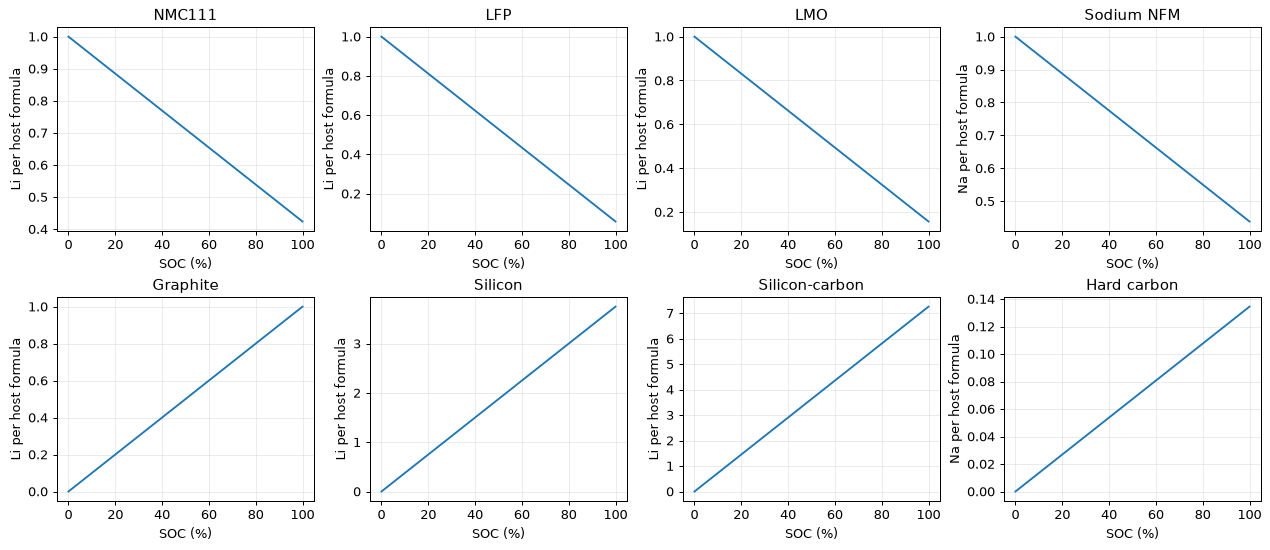

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)
soc = np.linspace(0, 1, 101)
for ax, chem in zip(axes.flat, scan.CHEMISTRIES):
    ax.plot(100*soc, scan.stoichiometry_from_soc(chem, soc))
    ax.set(title=chem.name, xlabel="SOC (%)", ylabel=f"{chem.mobile_ion} per host formula")
    ax.grid(alpha=0.25)
finish(fig, "stoichiometry_vs_soc")


## Surface maps and depth profiles

Disks have 10 mm diameter, 1 mm gaps and 1 mm holder margin. The default simulation raster is 100×100; maps below use a finer display grid. Separable radial and areal-depth modes act on mobile-ion atomic fraction and have zero mean over disk area and depth. Profiles stay within each chemistry's bounds; heterogeneity vanishes at 0% and 100% SOC.


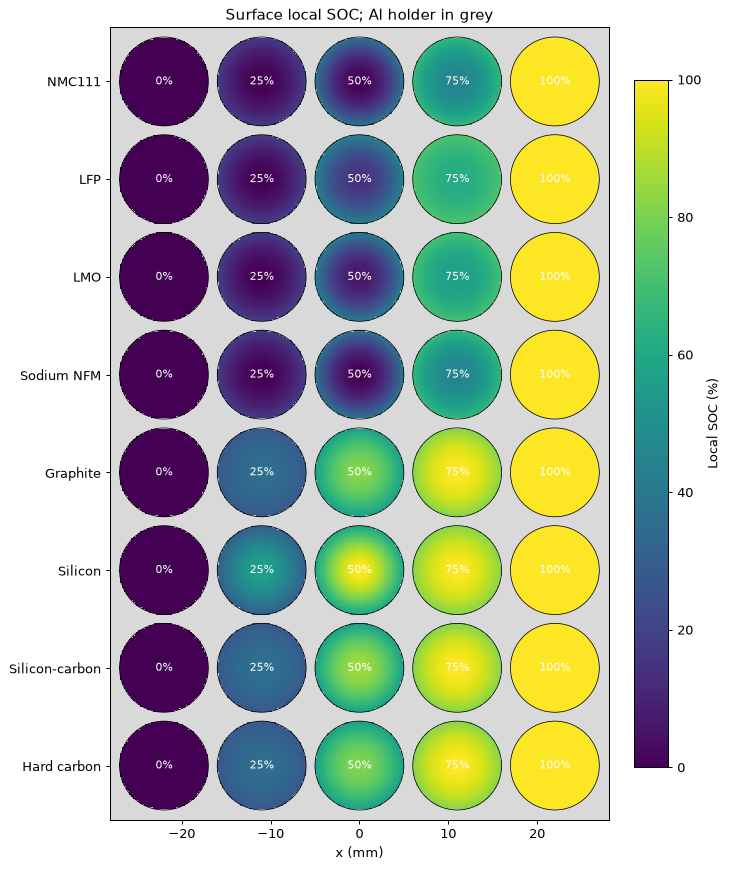

In [4]:
x, y = scan.array_scan_grid(280)
fractions = scan.array_composition(x, y, np.zeros_like(x))
ids = scan._array_cell_ids(x, y)
local_soc = np.full(x.shape, np.nan)
for cell in scan._ARRAY_CELLS:
    selected = ids == cell["cell_id"]
    chem = scan.CHEMISTRY_BY_NAME[cell["chemistry"]]
    local_soc[selected] = scan.soc_from_mobile_fraction(
        chem, fractions[..., scan.ARRAY_ELEMENTS.index(chem.mobile_ion)][selected])
fig, ax = plt.subplots(figsize=(8, 11), constrained_layout=True)
mesh = ax.pcolormesh(x, y, 100*local_soc, cmap="viridis", vmin=0, vmax=100, shading="auto")
for cell in scan._ARRAY_CELLS:
    cx, cy = cell["center_x_mm"], cell["center_y_mm"]
    ax.add_patch(Circle((cx, cy), 5, fill=False, lw=0.6))
    ax.text(cx, cy, f'{100*cell["soc"]:.0f}%', ha="center", va="center", color="white", fontsize=9)
ax.set_yticks([scan._ARRAY_CELLS[r*5]["center_y_mm"] for r in range(8)],
              [c.name for c in scan.CHEMISTRIES])
ax.set(aspect="equal", xlabel="x (mm)", title="Surface local SOC; Al holder in grey", facecolor="0.85")
fig.colorbar(mesh, ax=ax, label="Local SOC (%)", shrink=0.7)
finish(fig, "surface_soc_layout")


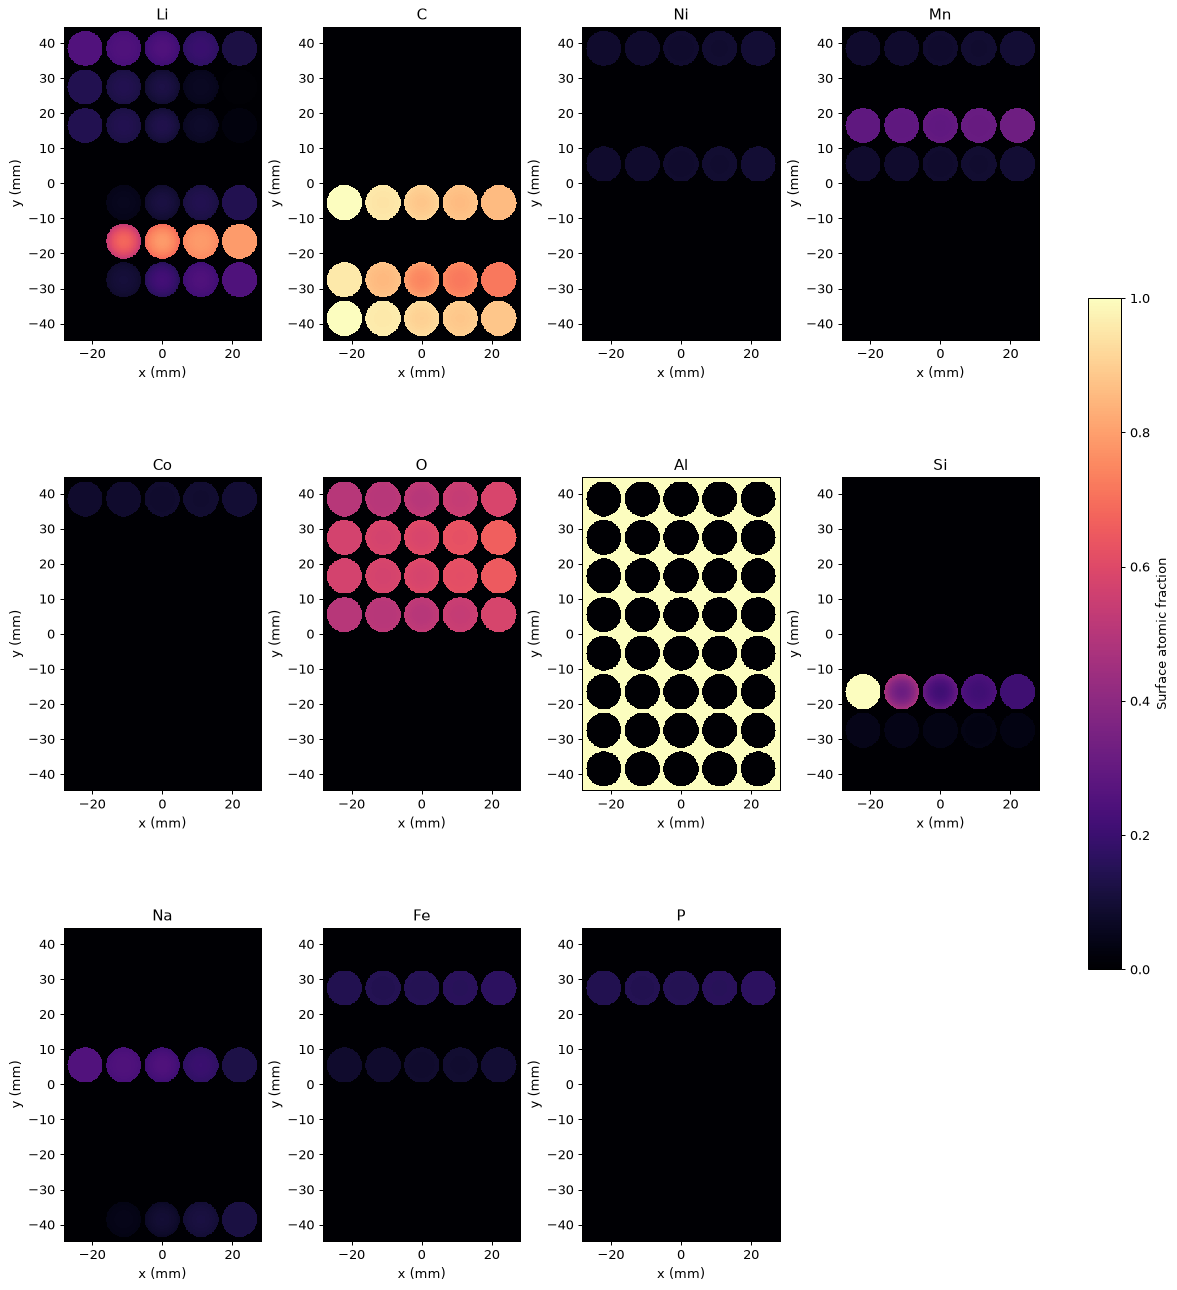

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(13, 15), constrained_layout=True)
for ax, element in zip(axes.flat, scan.ARRAY_ELEMENTS):
    mesh = ax.pcolormesh(x, y, fractions[..., scan.ARRAY_ELEMENTS.index(element)],
                         shading="auto", cmap="magma", vmin=0, vmax=1)
    ax.set(title=element, aspect="equal", xlabel="x (mm)", ylabel="y (mm)")
for ax in axes.flat[len(scan.ARRAY_ELEMENTS):]:
    ax.set_visible(False)
fig.colorbar(mesh, ax=list(axes.flat[:len(scan.ARRAY_ELEMENTS)]), label="Surface atomic fraction", shrink=0.5)
finish(fig, "surface_element_maps")


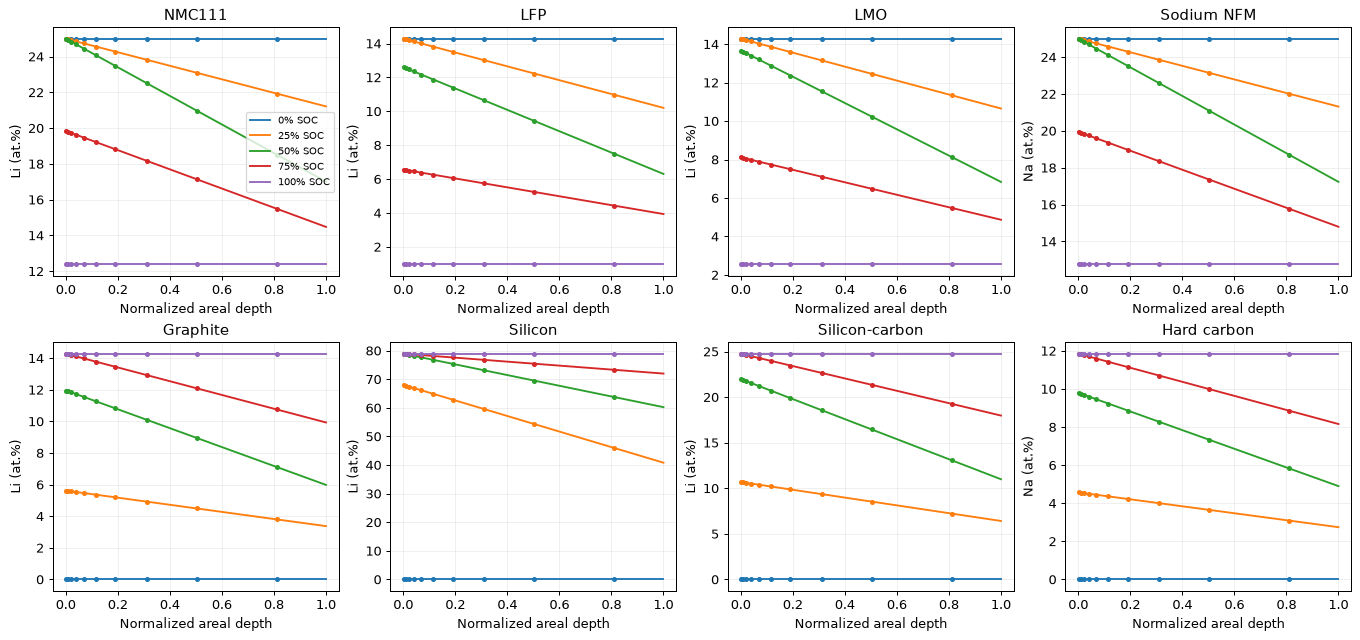

In [6]:
z = np.linspace(0, scan.MAX_DEPTH, 401)
thicknesses = scan.sublayer_thicknesses()
edges = np.r_[0, np.cumsum(thicknesses)]
midpoints = (edges[:-1] + edges[1:]) / 2
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
for row, (ax, chem) in enumerate(zip(axes.flat, scan.CHEMISTRIES)):
    for col, nominal_soc in enumerate(scan.ARRAY_SOC_VALUES):
        cell = scan._ARRAY_CELLS[row*scan.ARRAY_COLUMNS + col]
        cx, cy = cell["center_x_mm"], cell["center_y_mm"]
        idx = scan.ARRAY_ELEMENTS.index(chem.mobile_ion)
        f = scan.array_composition(cx, cy, z)[..., idx]
        line, = ax.plot(z/scan.MAX_DEPTH, 100*f, label=f"{100*nominal_soc:.0f}% SOC")
        layer_f = scan.array_sublayer_compositions(cx, cy)[:, idx]
        ax.plot(midpoints/scan.MAX_DEPTH, 100*layer_f, "o", ms=3, color=line.get_color())
    ax.set(title=chem.name, xlabel="Normalized areal depth", ylabel=f"{chem.mobile_ion} (at.%)")
    ax.grid(alpha=0.2)
axes.flat[0].legend(fontsize=8)
finish(fig, "center_depth_profiles")


## Integrated SOC verification

Average atomic fractions **before** converting to stoichiometry or SOC. Averaging local x or SOC is different. Uniform midpoint quadrature in r² integrates disk area. Ten layer midpoints and thickness weights exactly integrate the linear depth dependence. This checks all 40 disks independently.


Maximum absolute SOC error: 4.44e-16


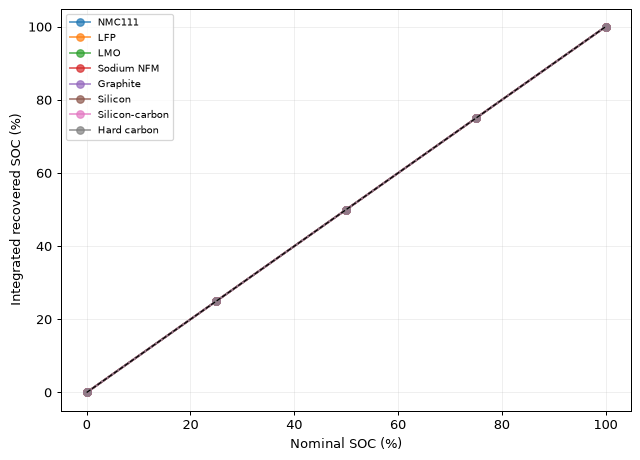

In [7]:
r = scan.CELL_DIAMETER_MM/2 * np.sqrt((np.arange(80)+0.5)/80)
errors = []
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for row, chem in enumerate(scan.CHEMISTRIES):
    recovered = []
    for col, expected in enumerate(scan.ARRAY_SOC_VALUES):
        cell = scan._ARRAY_CELLS[row*scan.ARRAY_COLUMNS + col]
        f = scan.array_composition(cell["center_x_mm"]+r[:, None], cell["center_y_mm"],
                                   midpoints[None, :])[..., scan.ARRAY_ELEMENTS.index(chem.mobile_ion)]
        mean_f = np.mean(np.average(f, axis=1, weights=thicknesses))
        value = float(scan.soc_from_mobile_fraction(chem, mean_f))
        recovered.append(value)
        errors.append(abs(value-expected))
    ax.plot(100*np.array(scan.ARRAY_SOC_VALUES), 100*np.array(recovered), "o-", label=chem.name, alpha=0.7)
ax.plot([0, 100], [0, 100], "k--", lw=1)
ax.set(xlabel="Nominal SOC (%)", ylabel="Integrated recovered SOC (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
assert max(errors) < 1e-12
print(f"Maximum absolute SOC error: {max(errors):.3g}")
finish(fig, "integrated_soc_check")


## Generate spectra separately

```powershell
python examples/generate_spatial_scan_more.py --dry-run --output examples/datasets/battery8_preview
python examples/generate_spatial_scan_more.py --sample-name Battery8 --output examples/datasets/battery8_scan
```

Dry-run writes model metadata only. The second command runs 16,000 SIMNRA positions and writes experimental-format `.dat` spectra plus `scan_metadata.json`. Use `--points 10` for a smaller 10?16 trial raster and `--no-poisson` for rounded expected counts. Spectrum generation requires SIMNRA. Output directories must not already exist.
